In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1)

In [2]:
listings_raw = pd.read_csv('../data/listings_clean_outlier.csv', parse_dates=['last_scraped', 'calendar_last_scraped', 'first_review', 'last_review'])
listings = listings_raw.copy()
print(listings.shape)

(4574, 74)


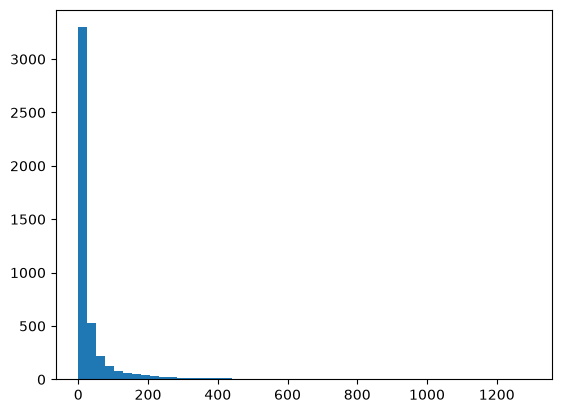

In [3]:
fig, ax = plt.subplots()
ax.hist(listings.number_of_reviews, bins=50)
plt.show()

In [4]:
sns.set_style("whitegrid", {
    "axes.facecolor": "#E5E3E9",
    "grid.color": "#404040",
    "grid.linewidth": 0.8,    
})

<Axes: xlabel='number_of_reviews', ylabel='Count'>

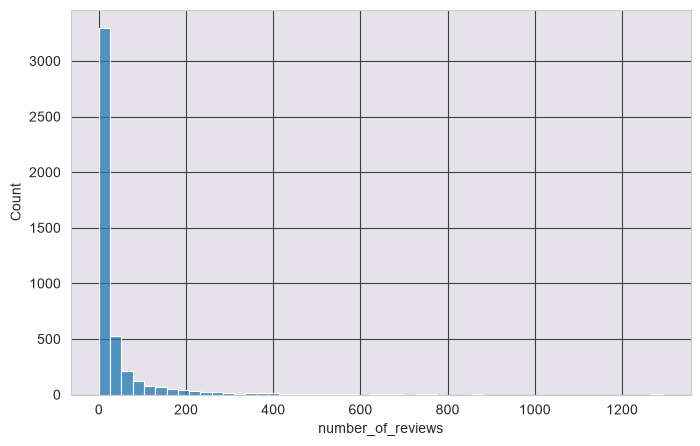

In [5]:
fig, ax = plt.subplots(figsize=(8,5))
sns.histplot(data=listings, x='number_of_reviews', bins=50, ax=ax)

# 2)

In [6]:
q1 = listings.number_of_reviews.quantile(0.25)
q3 = listings.number_of_reviews.quantile(0.75)
upper = q3 + 1.5 * (q3 - q1)
lower = q1 - 1.5 * (q3 - q1)
print(lower, upper)

-38.5 69.5


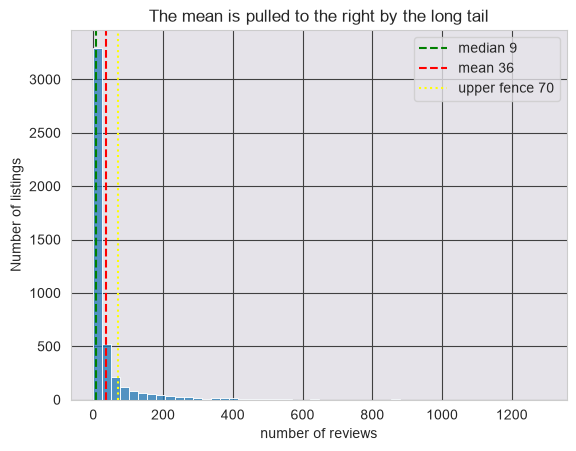

In [7]:
median = listings.number_of_reviews.median()
mean = listings.number_of_reviews.mean()
fig, ax = plt.subplots()
sns.histplot(data=listings, x='number_of_reviews', bins=50, ax=ax)
ax.axvline(median, color='green', linestyle='--', label=f'median {median:,.0f}')
ax.axvline(mean, color='red', linestyle='--', label=f'mean {mean:,.0f}')
ax.axvline(upper, color='yellow', linestyle=':', label=f'upper fence {upper:,.0f}')
ax.set_title('The mean is pulled to the right by the long tail')
ax.set_xlabel('number of reviews')
ax.set_ylabel('Number of listings')
ax.legend()
plt.show()

# 3)

In [8]:
print(listings.reviews_outlier.sum())

582


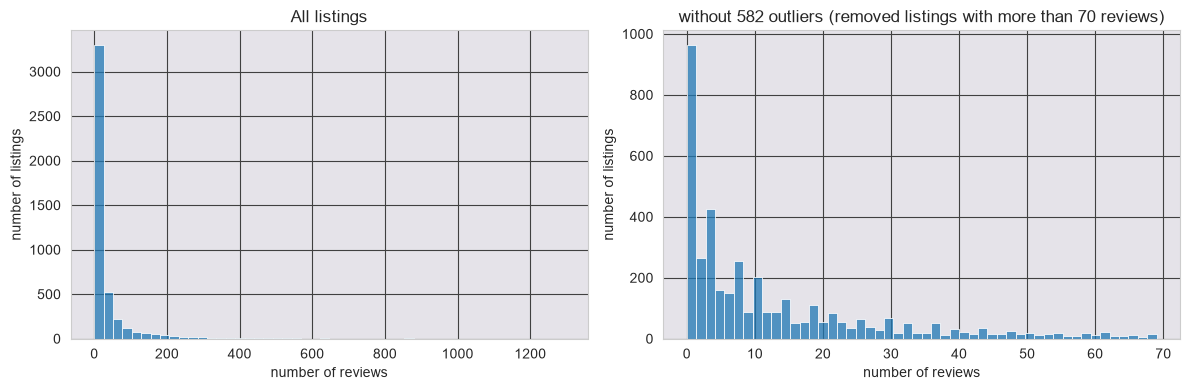

In [9]:
fig, axes = plt.subplots(1,2,figsize=(12,4))
#axes[0].set_xscale(value='log')
sns.histplot(data=listings, x='number_of_reviews', bins=50, ax=axes[0])
sns.histplot(data=listings[~listings.reviews_outlier],x='number_of_reviews', bins=50, ax=axes[1])
axes[0].set_title('All listings')
axes[1].set_title('without 582 outliers (removed listings with more than 70 reviews)')

for ax in axes:
    ax.set_xlabel('number of reviews')
    ax.set_ylabel('number of listings')
plt.tight_layout()
plt.show()

Right chart has more bins in the range 0-70 reviews, so it shows more details for that span

# 4)

In [69]:
listings.groupby('room_type').apply(lambda x: pd.Series(dict(
    over_300_reviews=((x.number_of_reviews > 300)).sum())))

,over_300_reviews
room_type,
Entire home/apt,77
Hotel room,0
Private room,13
Shared room,1


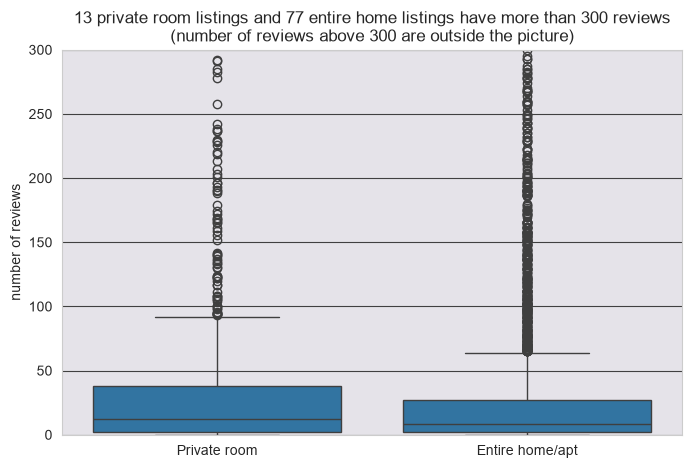

In [11]:
two_types = listings[listings.room_type.isin(['Entire home/apt', 'Private room'])]
fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(data=two_types, x='room_type', y='number_of_reviews', ax=ax)
ax.set_ylim(0,300)
#ax.set_yscale(value='log')
ax.set_title('13 private room listings and 77 entire home listings have more than 300 reviews\n(number of reviews above 300 are outside the picture)')
ax.set_xlabel('')
ax.set_ylabel('number of reviews')
plt.show()

# 5 a)

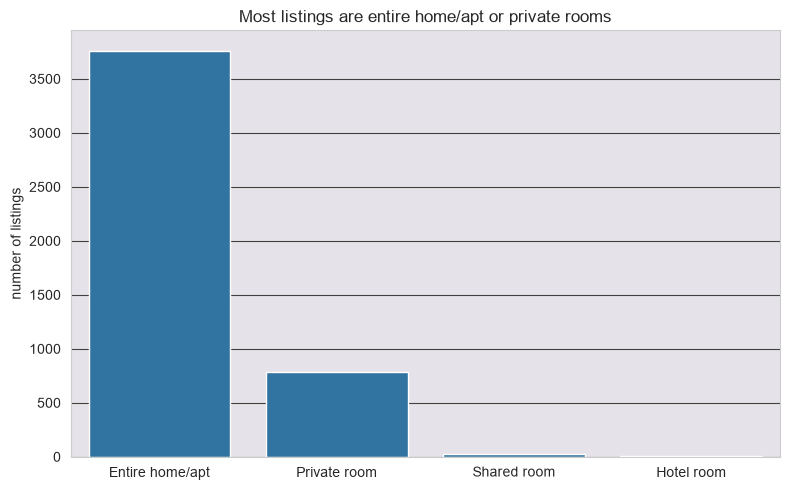

In [12]:
order = listings.room_type.value_counts().index
fig, ax = plt.subplots(figsize=(8,5))
sns.countplot(data=listings, x='room_type', order=order, ax=ax)
ax.set_title('Most listings are entire home/apt or private rooms')
ax.set_ylabel('number of listings')
ax.set_xlabel('')
plt.tight_layout()
plt.show()

# b)

In [13]:
by_area = (
    listings.groupby('neighbourhood_cleansed')['number_of_reviews'].agg(
        ['median', 'count']
    ).sort_values('median', ascending=False).reset_index()
)
by_area['label'] = by_area.neighbourhood_cleansed + '(' + by_area['count'].astype(str) + ')'
by_area

,neighbourhood_cleansed,median,count,label
0,Södermalms,17.0,1145,Södermalms(1145)
1,Kungsholmens,12.0,420,Kungsholmens(420)
2,Norrmalms,10.0,469,Norrmalms(469)
3,Östermalms,9.0,297,Östermalms(297)
4,Älvsjö,8.5,214,Älvsjö(214)
5,Hägersten-Liljeholmens,8.0,464,Hägersten-Liljeholmens(464)
6,Skarpnäcks,8.0,221,Skarpnäcks(221)
7,Spånga-Tensta,7.0,89,Spånga-Tensta(89)
8,Enskede-Årsta-Vantörs,7.0,445,Enskede-Årsta-Vantörs(445)
9,Bromma,5.0,281,Bromma(281)


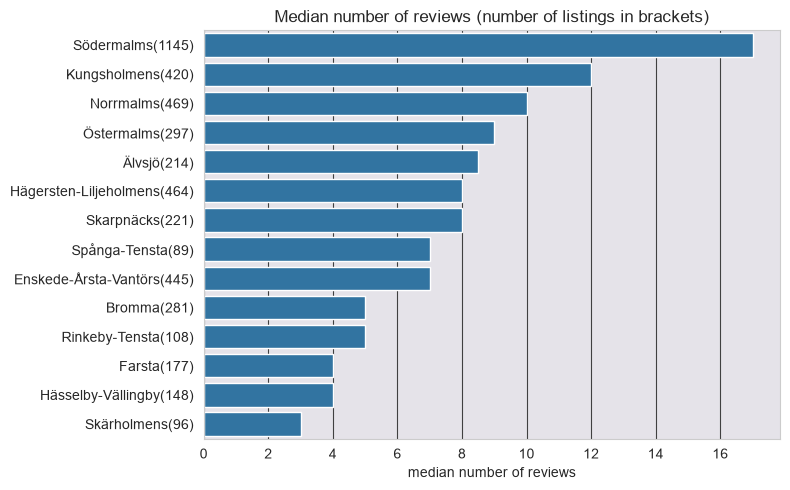

In [14]:
fig, ax = plt.subplots(figsize=(8,5))
sns.barplot(data=by_area, x='median', y='label', ax=ax)
ax.set_title('Median number of reviews (number of listings in brackets)')
ax.set_ylabel('')
ax.set_xlabel('median number of reviews')
plt.tight_layout()
plt.show()

# 6)

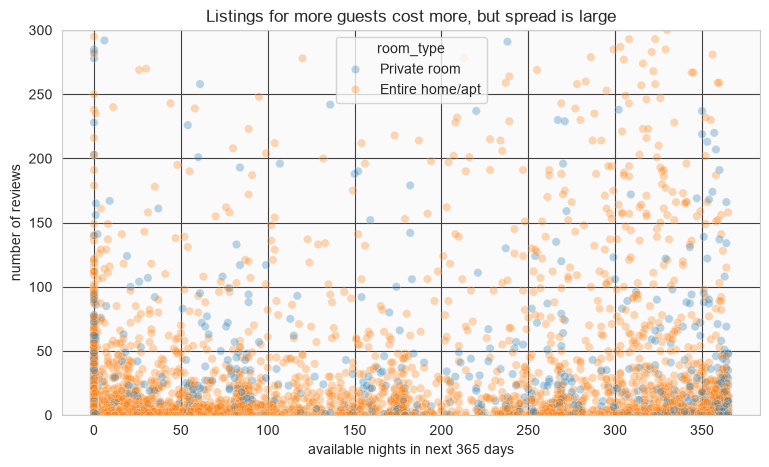

In [16]:
two_types = listings[listings.room_type.isin(['Entire home/apt', 'Private room'])]
fig, ax = plt.subplots(figsize=(9,5))
sns.scatterplot(data=two_types, x='availability_365', y='number_of_reviews', hue='room_type', alpha=0.3, ax=ax)
ax.set_ylim(0,300)
ax.set_title('Listings for more guests cost more, but spread is large')
ax.set_ylabel('number of reviews')
ax.set_xlabel('available nights in next 365 days')
plt.show()

No clear correlation between number of reviews and available_365

# 7 a)

In [18]:
listings.days_since_review.value_counts()

days_since_review
7 days      90
6 days      85
48 days     70
5 days      66
47 days     64
            ..
186 days     1
226 days     1
214 days     1
180 days     1
117 days     1
Name: count, Length: 910, dtype: int64

In [25]:
listings.days_since_review = pd.to_numeric(
    listings.days_since_review.str.replace(' ', '').str.replace('days', ''), errors='coerce')


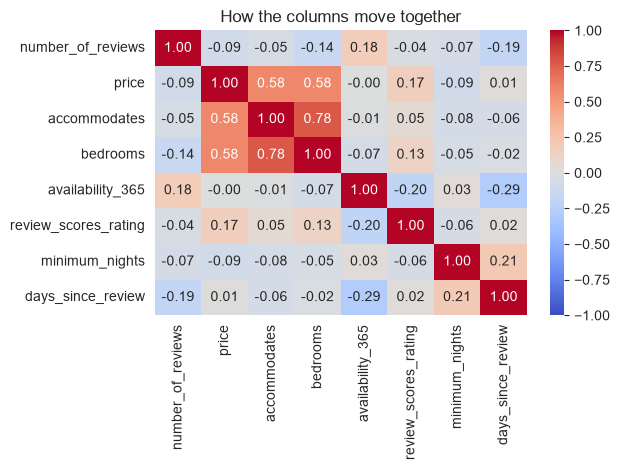

In [26]:
columns = ['number_of_reviews', 'price', 'accommodates', 'bedrooms', 'availability_365', 'review_scores_rating', 'minimum_nights', 'days_since_review']
corr = listings[columns].corr()
fig, ax = plt.subplots()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, ax=ax)
ax.set_title('How the columns move together')
plt.tight_layout()
plt.show()

# b)

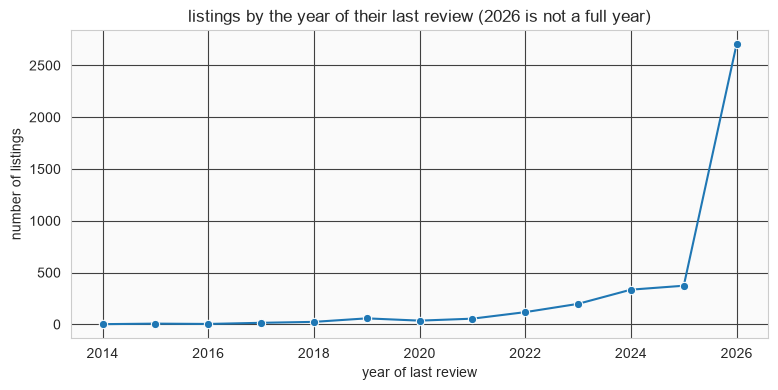

In [27]:
per_year = listings.last_review.dt.year.value_counts().sort_index()
fig, ax = plt.subplots(figsize=(9,4))
sns.lineplot(x=per_year.index, y=per_year.values, marker='o', ax=ax)
ax.set_title('listings by the year of their last review (2026 is not a full year)')
ax.set_ylabel('number of listings')
ax.set_xlabel('year of last review')
plt.show()

most listings that have at least one review also has at leat one review in 2026

# 8)

room_type
Entire home/apt    4.92
Private room       4.89
Name: review_scores_rating, dtype: float64


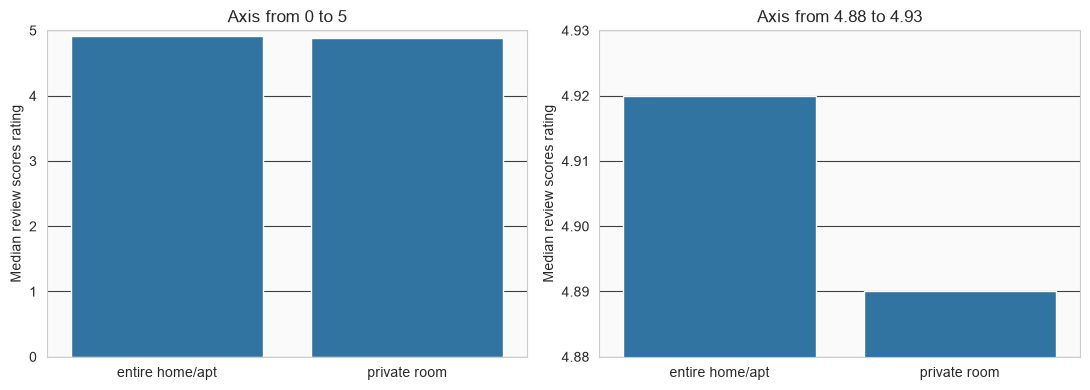

In [58]:
med_rev_scores = two_types.groupby('room_type')['review_scores_rating'].median()
print(med_rev_scores)
fig, axes = plt.subplots(1, 2, figsize=(11,4))
for ax in axes:
    sns.barplot(x=['entire home/apt', 'private room'], y=med_rev_scores.values, ax=ax)
    ax.set_ylabel('Median review scores rating')

axes[0].set_title('Axis from 0 to 5')
axes[1].set_title('Axis from 4.88 to 4.93')
axes[0].set_ylim(0, 5)
axes[1].set_ylim(4.88, 4.93)
plt.tight_layout()
plt.show()

room_type
Entire home/apt    4.92
Private room       4.89
Name: review_scores_rating, dtype: float64


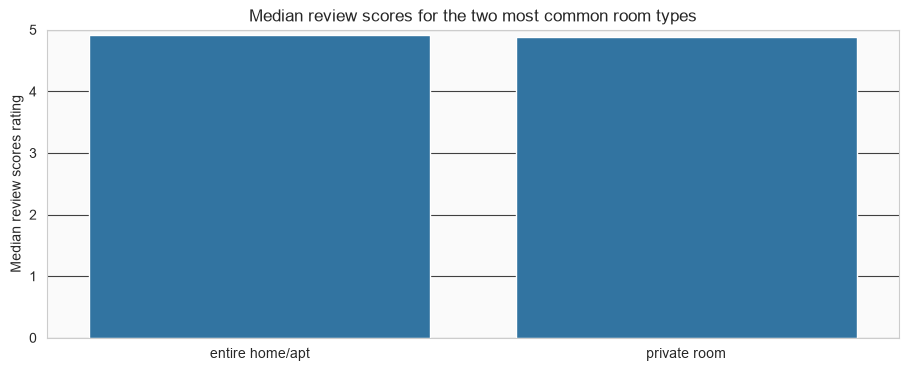

In [68]:
med_rev_scores = two_types.groupby('room_type')['review_scores_rating'].median()
print(med_rev_scores)
fig, ax = plt.subplots(1, figsize=(11,4))
sns.barplot(x=['entire home/apt', 'private room'], y=med_rev_scores.values, ax=ax)
ax.set_ylabel('Median review scores rating')
ax.set_title('Median review scores for the two most common room types')
ax.set_ylim(0, 5)
plt.savefig('../data/median_review_scores_two_types.png', dpi=150, bbox_inches='tight')